<a href="https://colab.research.google.com/github/tylerhuneke/linear-compartmental-models/blob/main/Linear_Compartmental_Model_Data_Gather_Template.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

Enter the number of compartments: 4



Enter 'cat' for catenary models. Enter 'cyc' for cycle models. Enter 'mam1' or 'mam2' for mammillary models (number is central compartment). To enter edges manually, press enter: cyc




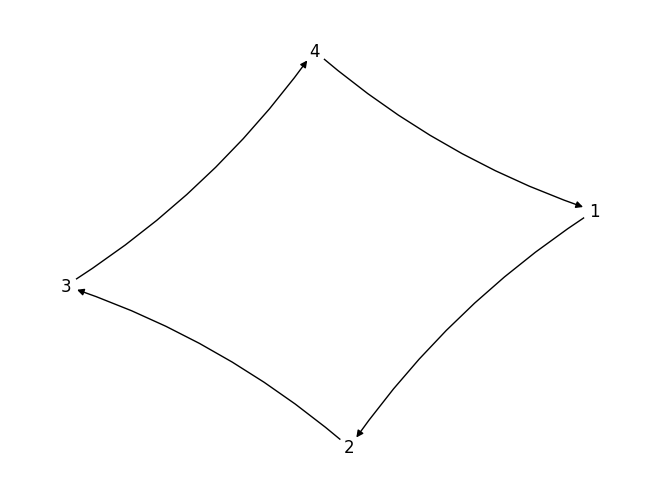

KeyboardInterrupt: Interrupted by user

In [ ]:
import networkx as nx
import matplotlib.pyplot as plt
import sympy as sp
import pandas as pd
from contextlib import redirect_stdout


def model_data(compartments, model_class, input_locations, output_locations, leak_locations):
  G = nx.MultiDiGraph()

  #Prompt for number of compartments
  # compartments = input("Enter the number of compartments: ")
  # compartments = int(compartments)
  # print("\n")

  # model_class = input("\nEnter 'cat' for catenary models. Enter 'cyc' for cycle models. To enter edges manually, press enter: ")

  #Catenary model template
  if model_class == "cat":
    #print("\n")
    for i in range(compartments):
      G.add_node(i+1)
    for i in range(compartments):
      if i == 0:
        G.add_edge(i+1, i+2)
      elif i == compartments - 1:
        G.add_edge(i+1, i)
      else:
        G.add_edge(i+1, i)
        G.add_edge(i+1, i+2)

  #Cycle model template
  elif model_class == "cyc":
    #print("\n")
    for i in range(compartments):
      G.add_node(i+1)
    for i in range(compartments):
      if i == compartments - 1:
        G.add_edge(i+1,1)
      else:
        G.add_edge(i+1, i+2)



  #Mammillary model template
  elif model_class == "mam1":
    print("\n")
    for i in range(compartments):
      G.add_node(i+1)
    j = 1
    while j < compartments:
      G.add_edge(1,j+1)
      G.add_edge(j+1,1)
      j+= 1

  elif model_class == "mam2":
    print("\n")
    for i in range(compartments):
      G.add_node(i+1)
    j = 1
    while j <= compartments:
      if j != 2:
        G.add_edge(2,j)
        G.add_edge(j,2)
      j += 1





  #Develop model by finding input, output, and leak locations
  Model = sp.zeros(compartments, 3)
  for i in input_locations:
    Model[i-1,0] = 1
  for i in output_locations:
    Model[i-1,1] = 1
  for i in leak_locations:
    if leak_location != 0:
      Model[i-1,2] = 1




  #Establish list of parameters
  parameters = []

  #define leak symbolic variables
  leaks = [None] * compartments

  for i in range(compartments):
    if Model[i,2] == 1:
      leaks[i] = sp.symbols("k_0_" + str(i+1))
      parameters.append(leaks[i])
    else:
      leaks[i] = 0


  #Create matrix A using edge data

  edges = nx.to_edgelist(G)

  A = sp.zeros(compartments, compartments)
  for (x,y,z) in edges:
    A[y-1,x-1] = sp.symbols("k_" + str(y) + "_" + str(x))
    parameters.append(A[y-1,x-1])
    A[x-1,x-1] -= sp.symbols("k_" + str(y) + "_" + str(x))
  for i in range(compartments):
    A[i,i] -= leaks[i]

  #print("\n\n\nA = \n")
  #sp.pprint(A, num_columns = 100000)
  # print("\n\n\n")
  A_text = open("A.txt", "w")
  with redirect_stdout(A_text):
    sp.pprint(A, num_columns = 100000)
  A_text.close()
  A_read = open("A.txt", "r")
  A_lines = A_read.readlines()
  A_final = ""
  for line in A_lines:
    A_final = A_final + line
  A_read.close()




  #Define B = dI-A matrix
  d = sp.symbols("d")
  B = d * sp.eye(compartments) - A
  #print("dI - A = \n")
  #sp.pprint(B,num_columns = 100000)
  B_text = open("B.txt", "w")
  with redirect_stdout(B_text):
    sp.pprint(B,num_columns = 100000)
  B_text.close()
  B_read = open("B.txt", "r")
  B_lines = B_read.readlines()
  B_final = ""
  for line in B_lines:
    B_final = B_final + line
  B_read.close()



  #Define compartment value vector x
  x = sp.zeros(compartments, 1)
  for i in range(compartments):
    x[i] = sp.symbols("x" + str(i+1))




  #Print SIAN input-output equations
 # print("\n\n\nThe ODEs for SIAN are: \n")
  sian_code = open("sian_code.txt", "w")
  for i in range(compartments):
    if Model[i,0] == 1:
      print("dx" + str(i+1) + "/dt = " + str((A[i,:]*x)[0,0]) + " + u" + str(i+1) + "(t),", file = sian_code)
    else:
      print("dx" + str(i+1) + "/dt = " + str((A[i,:]*x)[0,0]) + ",", file = sian_code)
    if Model[i,1] == 1:
      print("y" + str(i+1) + " = " + str(x[i]) + ",", file = sian_code)

  sian_code.close()
  sian_text = open("sian_code.txt", "r")

  sian_script = sian_text.read()
  sian_text.close()


  #Print Julia Input-Output Equations
 # print("\n\n\nThe ODEs for Juila are: \n")

  #Reading julia code into text file for evaluation
  julia_code = open("julia_code.txt", "w")
  print("ode = @ODEmodel(", file = julia_code)
  for i in range(compartments):
    if Model[i,0] == 1:
      string = "x" + str(i+1) + "'(t) = " + str((A[i,:]*x)[0,0]) + " + u" + str(i+1) + "(t), "
      for j in range(compartments):
        string = string.replace("x" + str(j+1), "x" + str(j+1) + "(t)")
        string = string.replace("x" + str(i+1) + "(t)'(t) = ", "x" + str(i+1) + "'(t) = ")
      print(string, file = julia_code)
    else:
      string = "x" + str(i+1) + "'(t) = " + str((A[i,:]*x)[0,0]) + ", "
      for j in range(compartments):
        string = string.replace("x" + str(j+1), "x" + str(j+1) + "(t)")
        string = string.replace("x" + str(i+1) + "(t)'(t) = ", "x" + str(i+1) + "'(t) = ")
      print(string, file = julia_code)
    if Model[i,1] == 1:
      print("y" + str(i+1) + "(t) = " + str(x[i]) + "(t), ", file = julia_code)
  print(")\n\n\n", file = julia_code)

  julia_code.close()
  julia_text = open("julia_code.txt", "r")

  julia_script = julia_text.read()
  julia_text.close()


  #find coefficient map
  coefficients = []
  LHS = sp.expand(B.det())
  # print("The left-hand side of the input-output equations is: \n")
  # print(LHS)
  i = compartments
  while i >= 0:
    j = LHS.coeff(d,i)
    if j != 0 and j!= 1:
      coefficients.append(j)
    i -= 1

  #print("\n\n\nRight-hand side of the input-output equation(s):")
  for i in range(compartments):
    if Model[i,0] == 1:
      for j in range(compartments):
        submatrix = B.copy()
        if Model[j,1] == 1:
          submatrix.row_del(i)
          submatrix.col_del(j)
          RHS = sp.expand((-1)**(i+j)*submatrix.det())
         # print("\n"+str(RHS))
          n = compartments
          while n >= 0:
            k = RHS.coeff(d,n)
            if k != 0 and k!= 1:
              coefficients.append(k)
            n -= 1





  coeff_map = sp.Matrix(coefficients)
  #print("\n\n\nThe coefficient map is:\n")
  coeff_text = open("coeff_map.txt", "w")
  with redirect_stdout(coeff_text):
    sp.pprint(coeff_map, num_columns = 100000)
  coeff_text.close()
  coeff_read = open("coeff_map.txt", "r")
  coeff_map = coeff_read.read()
  coeff_read.close()





  return A_final, B_final, coeff_map, julia_script, sian_script


# Create dataframe with pandas to test class of models
data = []


#Sample model included below is the 4-compartment cycle model. Changing inputs

#Enter number of compartments to begin with below
compartments = 4
#Enter "cyc" for cycle models, "mam1" or "mam2" for mammillary models (see above for details) or "cat" for catenary models
model_class = "cyc"
#Enter maximum compartments to test below
while compartments <= 4:
  input_list = [[1],[1,2],[1,3],[1,4],[1,2,3],[1,2,4],[1,3,4],[1,2,3,4]] #Fixed at compartment 1 for cycle models
  #Enter starting output location below and iterate for all except input compartment (compartment 1)
  output_list = [[1],[2],[3],[4],[1,2],[1,3],[1,4],[2,3],[2,4],[3,4],[1,2,3],[1,2,4],[1,3,4],[2,3,4],[1,2,3,4]]
  leak_list = [[0],[1],[2],[3],[4],[1,2],[1,3],[1,4],[2,3],[2,4],[3,4],[1,2,3],[1,2,4],[1,3,4],[2,3,4],[1,2,3,4]]
  for input_location in input_list:
    for output_location in output_list:
      for leak_location in leak_list:
        current_data = model_data(compartments, model_class, input_location, output_location, leak_location)
        data.append([compartments, model_class, input_location, output_location, leak_location, [current_data[0]], [current_data[1]], current_data[2], current_data[4], current_data[3]])
  compartments += 1
dataframe = pd.DataFrame(data, columns = ["compartments", "model class", "input location", "output location", "leak location", "A Matrix", "dI-A Matrix", "Coefficient Map", "SIAN Code", "Julia Code"])
dataframe.to_excel("model_data.xlsx",index = False)

